In [6]:
import pandas as pd

In [7]:
customers = pd.read_csv("customers_raw.csv")

In [8]:
customers.head(20)

,customer_id,first_name,last_name,email,city,signup_date,loyalty_member
0,C1000,David,Khan,NaN,new york,10/28/2024,No
1,C1001,Raj,Johnson,raj.johnson@gmail.com,new york,08-08-2023,No
2,C1002,Mary,Hassan,mary.hassan@gmail.com,Seattle,2023-08-17,No
3,C1003,Mary,Davis,mary.davis@gmail.com,LOS ANGELES,2024-07-24,Y
4,C1004,Mia,Garcia,mia.garcia@gmail.com,New York,2024-08-18,Yes
5,C1005,Raj,Johnson,raj.johnson@gmail.com,Austin,30-07-2023,No
6,C1006,Sofia,Kumar,sofia.kumar@gmail.com,LOS ANGELES,2025-03-24,No
7,C1007,David,Wang,david.wang@gmail.com,Chicago,09/15/2024,Yes
8,C1008,Olivia,Clark,olivia.clark@gmail.com,Chicago,2024-11-15,No
9,C1009,David,Martinez,david.martinez@gmail.com,New York,23-05-2024,Y


In [9]:
orders = pd.read_csv("orders_raw.csv")

In [10]:
orders.head(20)

,order_id,customer_id,store_id,order_date,category,quantity,revenue,is_return
0,ORD100000,C1310,ST09,2024-09-30,home goods,5,640.25,No
1,ORD100001,C1141,ST05,31-05-2024,Home Goods,2,45.62,No
2,ORD100002,C1566,ST13,2025-03-03,Furniture,4,136.0,No
3,ORD100003,C2006,ST14,2025-05-22,Kitchen,2,91.76,No
4,ORD100004,C1437,ST13,2024-10-27,Electronics,4,70.48,No
5,ORD100005,C1322,ONLINE,01/09/2025,Home Goods,4,132.68,No
6,ORD100006,C1146,ST14,2024-04-24,home goods,3,$99.27,No
7,ORD100007,C1144,ST09,04/28/2025,ELECTRONICS,2,16.28,No
8,ORD100008,C1085,ONLINE,2025-09-25,Electronics,1,74.75,No
9,ORD100009,C1191,ONLINE,09-01-2025,ELECTRONICS,3,160.62,No


In [18]:
def clean_revenue (value):
    if pd.isnull(value):
        return None
    value = str(value)
    value = value.replace('$', '').replace('USD','').strip()
    return float(value)
orders['revenue_clean'] = orders['revenue'].apply(clean_revenue)
orders[['revenue','revenue_clean']].sample(10)

,revenue,revenue_clean
4755,28221.75,28221.75
8948,$132.68,132.68
7384,252.15,252.15
489,$74.94,74.94
7535,24.17,24.17
8728,259.23,259.23
6428,611.45,611.45
7537,96.54,96.54
5926,59.2,59.20
2478,60.0,60.00


In [19]:
orders.dtypes

order_id          object
customer_id       object
store_id          object
order_date        object
category          object
quantity           int64
revenue           object
is_return         object
revenue_clean    float64
dtype: object

In [22]:
orders['order_date_clean'] = pd.to_datetime(orders['order_date'],format='mixed', errors='coerce')
orders[['order_date', 'order_date_clean']].sample (10)

,order_date,order_date_clean
702,2025-06-29,NaT
4217,18-03-2025,NaT
777,03/15/2025,NaT
2444,27-03-2024,NaT
254,2024-03-01,NaT
5310,2024-11-21,NaT
8799,06/06/2024,NaT
5073,22-03-2025,NaT
7337,03/01/2025,NaT
2961,03/17/2025,NaT


In [23]:
import pandas as pd
print(pd.__version__)

1.4.2


In [24]:
from dateutil import parser

def parse_date_safe(value):
    try:
        return parser.parse(str(value))
    except Exception:
        return None

orders['order_date_clean'] = orders['order_date'].apply(parse_date_safe)
orders[['order_date', 'order_date_clean']].sample(10)

,order_date,order_date_clean
1445,08/07/2024,2024-08-07
3584,2024/10/18,2024-10-18
5154,2024/07/22,2024-07-22
2510,2024/06/14,2024-06-14
2067,23-08-2025,2025-08-23
5584,2024-01-15,2024-01-15
7412,17-12-2024,2024-12-17
7320,2025/04/20,2025-04-20
978,04/18/2024,2024-04-18
8488,02/19/2025,2025-02-19


In [25]:
orders['order_date_clean'].isnull().sum()

0

In [27]:
orders['category_clean'] = orders['category'].str.strip().str.title()
orders['category_clean'].value_counts()

Electronics    3803
Home Goods     2479
Kitchen        1317
Furniture      1236
Name: category_clean, dtype: int64

In [29]:
orders['category_clean'].sample(10)

2520      Furniture
5840    Electronics
8369      Furniture
5122        Kitchen
4068    Electronics
5789        Kitchen
5592     Home Goods
6730    Electronics
60        Furniture
5891     Home Goods
Name: category_clean, dtype: object

In [34]:
orders['quantity_clean'] = orders['quantity'].where(
    (orders['quantity'] > 0) & (orders['quantity'] <= 20),
    other = None
)
orders['quantity_clean'].describe()

count    8638.000000
mean        2.979162
std         1.417576
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: quantity_clean, dtype: float64

In [36]:
orders['quantity_clean'].sample(20)

4570    3.0
5267    3.0
1320    3.0
1148    3.0
7152    1.0
310     1.0
3207    1.0
2937    1.0
8440    2.0
6796    3.0
3331    4.0
3769    5.0
6955    4.0
4717    1.0
8784    2.0
8427    4.0
5176    2.0
4657    5.0
4578    4.0
5828    2.0
Name: quantity_clean, dtype: float64

In [37]:
orders['is_return'].unique()

array(['No', 'yes', 'Yes'], dtype=object)

In [39]:
orders['is_return_clean'] =orders['is_return'].str.strip().str.capitalize()
orders['is_return_clean'].unique()

array(['No', 'Yes'], dtype=object)

In [41]:
customers['city'].unique()

array(['new york', 'Seattle', 'LOS ANGELES', 'New York', 'Austin',
       'Chicago', 'Denver', 'Phoenix', 'Houston', 'San Diego', 'chicago',
       'Dallas', 'dallas', 'san diego', 'denver', 'houston',
       'los angeles', 'phoenix', 'austin', 'seattle'], dtype=object)

In [42]:
customers['city_clean'] = customers['city'].str.strip().str.title()
customers['city_clean'].unique()

array(['New York', 'Seattle', 'Los Angeles', 'Austin', 'Chicago',
       'Denver', 'Phoenix', 'Houston', 'San Diego', 'Dallas'],
      dtype=object)

In [49]:
loyalty_map ={
    'Yes': 'Yes', 'Y': 'Yes',
    'No': 'No', 'N': 'No'
}

customers['loyalty_clean'] = customers['loyalty_member'].map(loyalty_map)
customers['loyalty_clean'].unique()

array(['No', 'Yes', nan], dtype=object)

In [51]:
customers['customer_id'].duplicated().sum()

40

In [56]:
dup_ids = customers[customers['customer_id'].duplicated(keep=False)]
dup_ids.sort_values('customer_id').head(10)

,customer_id,first_name,last_name,email,city,signup_date,loyalty_member,city_clean,loyalty_clean
30,C1030,Liam,Ali,liam.ali@gmail.com,Denver,28-03-2023,NaN,Denver,NaN
1233,C1030,Liam,Ali,liam.ali@gmail.com,denver,28-03-2023,NaN,Denver,NaN
118,C1118,Noah,Garcia,noah.garcia@gmail.com,Phoenix,09/09/2024,NaN,Phoenix,NaN
1229,C1118,Noah,Garcia,noah.garcia@gmail.com,phoenix,09/09/2024,NaN,Phoenix,NaN
123,C1123,Aisha,Clark,aisha.clark@gmail.com,Denver,2023-11-16,No,Denver,No
1211,C1123,AISHA,Clark,aisha.clark@gmail.com,denver,2023-11-16,No,Denver,No
1204,C1128,AISHA,Khan,NaN,san diego,2024-05-09,No,San Diego,No
128,C1128,Aisha,Khan,NaN,San Diego,2024-05-09,No,San Diego,No
142,C1142,Priya,Nguyen,priya.nguyen@gmail.com,San Diego,2024-10-13,Yes,San Diego,Yes
1220,C1142,Priya,Nguyen,priya.nguyen@gmail.com,san diego,2024-10-13,Yes,San Diego,Yes


In [58]:
customers['customer_id'].duplicanoted().sum()

40

In [59]:
customers['customer_id'].value_counts()

C1030    2
C1190    2
C1287    2
C1552    2
C1142    2
        ..
C1406    1
C1405    1
C1404    1
C1403    1
C2199    1
Name: customer_id, Length: 1200, dtype: int64

In [61]:
customers['customer_id'].duplicated(keep=False).sum()

80

In [62]:
customers_dedup = customers.drop_duplicates(subset='customer_id', keep ='first')
print("Before:",len(customers))
print("After:", len(customers_dedup))

Before: 1240
After: 1200


In [69]:
orders_final = orders[['order_id', 'customer_id', 'store_id', 'order_date_clean',
                        'category_clean', 'quantity_clean', 'revenue_clean', 'is_return_clean']].copy()

customers_final = customers_dedup[['customer_id', 'first_name', 'last_name', 'email',
                                    'city_clean', 'signup_date', 'loyalty_clean']].copy()

orders_final.to_csv('orders_clean.csv', index=False)
customers_final.to_csv('customers_clean.csv', index=False)

print("Saved. Orders:", orders_final.shape, "| Customers:", customers_final.shape)

Saved. Orders: (9015, 8) | Customers: (1200, 7)


In [71]:
orders_final.head(20)

,order_id,customer_id,store_id,order_date_clean,category_clean,quantity_clean,revenue_clean,is_return_clean
0,ORD100000,C1310,ST09,2024-09-30,Home Goods,5.0,640.25,No
1,ORD100001,C1141,ST05,2024-05-31,Home Goods,2.0,45.62,No
2,ORD100002,C1566,ST13,2025-03-03,Furniture,4.0,136.00,No
3,ORD100003,C2006,ST14,2025-05-22,Kitchen,2.0,91.76,No
4,ORD100004,C1437,ST13,2024-10-27,Electronics,4.0,70.48,No
5,ORD100005,C1322,ONLINE,2025-01-09,Home Goods,4.0,132.68,No
6,ORD100006,C1146,ST14,2024-04-24,Home Goods,3.0,99.27,No
7,ORD100007,C1144,ST09,2025-04-28,Electronics,2.0,16.28,No
8,ORD100008,C1085,ONLINE,2025-09-25,Electronics,1.0,74.75,No
9,ORD100009,C1191,ONLINE,2025-09-01,Electronics,3.0,160.62,No


In [72]:
customers_final.head(20)

,customer_id,first_name,last_name,email,city_clean,signup_date,loyalty_clean
0,C1000,David,Khan,NaN,New York,10/28/2024,No
1,C1001,Raj,Johnson,raj.johnson@gmail.com,New York,08-08-2023,No
2,C1002,Mary,Hassan,mary.hassan@gmail.com,Seattle,2023-08-17,No
3,C1003,Mary,Davis,mary.davis@gmail.com,Los Angeles,2024-07-24,Yes
4,C1004,Mia,Garcia,mia.garcia@gmail.com,New York,2024-08-18,Yes
5,C1005,Raj,Johnson,raj.johnson@gmail.com,Austin,30-07-2023,No
6,C1006,Sofia,Kumar,sofia.kumar@gmail.com,Los Angeles,2025-03-24,No
7,C1007,David,Wang,david.wang@gmail.com,Chicago,09/15/2024,Yes
8,C1008,Olivia,Clark,olivia.clark@gmail.com,Chicago,2024-11-15,No
9,C1009,David,Martinez,david.martinez@gmail.com,New York,23-05-2024,Yes


In [74]:
#Find each customer's last order date

last_order = orders_final.groupby('customer_id')['order_date_clean'].max().reset_index()
last_order.columns = ['customer_id', 'last_order_date']
last_order.head()

,customer_id,last_order_date
0,C1000,2025-09-27
1,C1001,2025-08-31
2,C1002,2025-07-27
3,C1003,2025-10-02
4,C1004,2025-08-20


In [78]:
#Calculate days since last order and flag at-risk loyalty members

last_order['last_order_date'] = pd.to_datetime(last_order['last_order_date'])
reference_date = orders_final['order_date_clean'].max()
print("Reference date:", reference_date)

last_order['days_since_last_order'] = (reference_date - last_order['last_order_date']).dt.days
last_order.head()

Reference date: 2025-12-09 00:00:00


,customer_id,last_order_date,days_since_last_order
0,C1000,2025-09-27,73
1,C1001,2025-08-31,100
2,C1002,2025-07-27,135
3,C1003,2025-10-02,68
4,C1004,2025-08-20,111


In [79]:
print("Before:", len(orders_final))
orders_final = orders_final.drop_duplicates(subset='order_id', keep='first')
print("After:", len(orders_final))

Before: 9015
After: 9000


In [80]:
#Build the store-level table
store_orders = orders_final[
    (orders_final['store_id'].notnull()) &
    (orders_final['store_id'] != 'ONLINE') &
    (orders_final['is_return_clean'] != 'Yes') &
    (orders_final['quantity_clean'].notnull()) &
    (orders_final['revenue_clean'].notnull())
]

store_summary = store_orders.groupby('store_id').agg(
    total_revenue=('revenue_clean', 'sum'),
    num_orders=('order_id', 'count'),
    avg_order_value=('revenue_clean', 'mean')
).reset_index()

store_summary = store_summary.sort_values('total_revenue')
store_summary

,store_id,total_revenue,num_orders,avg_order_value
1,ST02,45525.18,376,121.077606
3,ST04,46419.82,386,120.258601
13,ST14,48500.75,374,129.681150
4,ST05,49545.05,364,136.112775
2,ST03,49837.21,389,128.116221
8,ST09,49894.19,379,131.646939
5,ST06,51031.20,370,137.922162
10,ST11,51992.15,403,129.012779
7,ST08,52118.84,377,138.246260
11,ST12,52797.53,398,132.657111


In [81]:
#Find the bottom 20% and answer "traffic or basket size?"
cutoff = store_summary['total_revenue'].quantile(0.20)
store_summary['underperforming'] = store_summary['total_revenue'] <= cutoff

print("Cutoff revenue:", cutoff)
store_summary[store_summary['underperforming']]

Cutoff revenue: 49336.19


,store_id,total_revenue,num_orders,avg_order_value,underperforming
1,ST02,45525.18,376,121.077606,True
3,ST04,46419.82,386,120.258601,True
13,ST14,48500.75,374,129.681150,True


In [82]:
#Fix the dates (one small correction)
def parse_date_exact(value):
    if pd.isna(value):
        return pd.NaT
    s = str(value).strip()
    for fmt in ('%Y-%m-%d', '%Y/%m/%d', '%m/%d/%Y', '%d-%m-%Y'):
        try:
            return pd.to_datetime(s, format=fmt)
        except ValueError:
            continue
    return pd.NaT

orders['order_date_clean'] = orders['order_date'].apply(parse_date_exact)
orders['order_date_clean'].isnull().sum()

0

In [83]:
#The Finance Director's question, easy version
returns = (orders_final['is_return_clean'] == 'Yes').sum()
total = len(orders_final)
print("Returned orders:", returns)
print("Total orders:", total)
print("Return rate:", round(returns / total * 100, 1), "%")

Returned orders: 908
Total orders: 9000
Return rate: 10.1 %


In [88]:
# 1. Recreate the return flag (1 = returned, 0 = not returned)
orders_final['is_return_flag'] = (orders_final['is_return_clean'] == 'Yes').astype(int)

# 2. Rebuild same_months so it includes the new column
same_months = orders_final[orders_final['month'] <= last_month]

# 3. Check the column is there
same_months.columns

Index(['order_id', 'customer_id', 'store_id', 'order_date_clean',
       'category_clean', 'quantity_clean', 'revenue_clean', 'is_return_clean',
       'year', 'month', 'is_return_flag'],
      dtype='object')

In [89]:
orders_final['order_date_clean'] = pd.to_datetime(orders_final['order_date_clean'])
orders_final['year'] = orders_final['order_date_clean'].dt.year
orders_final['month'] = orders_final['order_date_clean'].dt.month
last_month = orders_final[orders_final['year'] == 2025]['month'].max()

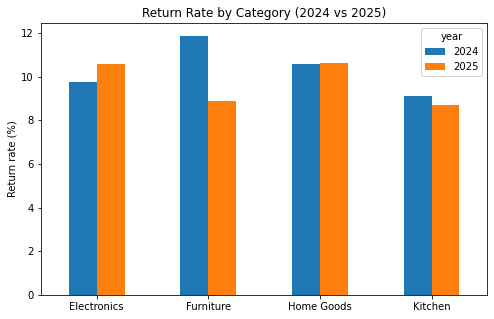

In [90]:
#the return rate for each category, with 2024 and 2025 side by side.

import matplotlib.pyplot as plt

chart_data = same_months.groupby(['category_clean', 'year'])['is_return_flag'].mean().unstack() * 100

chart_data.plot(kind='bar', figsize=(8, 5))
plt.title('Return Rate by Category (2024 vs 2025)')
plt.ylabel('Return rate (%)')
plt.xlabel('')
plt.xticks(rotation=0)
plt.savefig('return_rate_by_category.png')
plt.show()

In [91]:
#Remove duplicate orders and build the store table
orders_final = orders_final.drop_duplicates(subset='order_id')

store_orders = orders_final[
    (orders_final['store_id'].notnull()) &
    (orders_final['store_id'] != 'ONLINE') &
    (orders_final['is_return_clean'] != 'Yes') &
    (orders_final['quantity_clean'].notnull()) &
    (orders_final['revenue_clean'].notnull())
]

store_summary = store_orders.groupby('store_id').agg(
    total_revenue=('revenue_clean', 'sum'),
    num_orders=('order_id', 'count'),
    avg_order_value=('revenue_clean', 'mean')
).reset_index()

store_summary.sort_values('total_revenue')

,store_id,total_revenue,num_orders,avg_order_value
1,ST02,45525.18,376,121.077606
3,ST04,46419.82,386,120.258601
13,ST14,48500.75,374,129.681150
4,ST05,49545.05,364,136.112775
2,ST03,49837.21,389,128.116221
8,ST09,49894.19,379,131.646939
5,ST06,51031.20,370,137.922162
10,ST11,51992.15,403,129.012779
7,ST08,52118.84,377,138.246260
11,ST12,52797.53,398,132.657111


In [92]:
cutoff = store_summary['total_revenue'].quantile(0.20)
store_summary['underperforming'] = store_summary['total_revenue'] <= cutoff
store_summary[store_summary['underperforming']]

,store_id,total_revenue,num_orders,avg_order_value,underperforming
1,ST02,45525.18,376,121.077606,True
3,ST04,46419.82,386,120.258601,True
13,ST14,48500.75,374,129.681150,True
